<a href="https://colab.research.google.com/github/manjunadha12/CSA4703-Deep-Learning/blob/main/Lab/Exp16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

X_train: (554, 30, 1), y_train: (554, 1)
X_test : (116, 30, 1),  y_test : (116, 1)

=== SimpleRNN vs LSTM Performance Comparison ===
    Model  Units  Params  Train Loss (MSE)  Val Loss (MSE)  Train Time (s)   MAE  RMSE  MAPE (%)
SimpleRNN     32    1121           0.00271         0.00215            9.03 70.89 98.28      4.65
     LSTM     32    4385           0.00302         0.00184           12.30 64.44 95.69      4.29


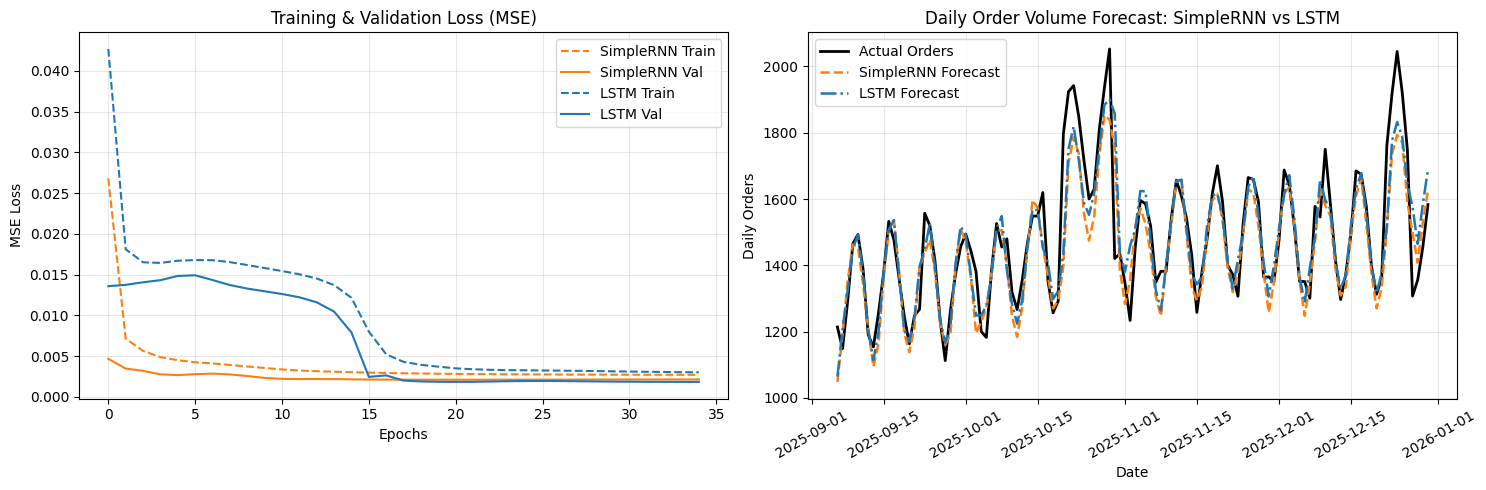

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# ==========================================
# Generate 2 Years of Daily Food-Delivery Orders
# ==========================================
n_days = 730
dates = pd.date_range(start="2024-01-01", periods=n_days, freq="D")
t = np.arange(n_days)

# Base trend + weekly cycle (weekend spikes) + annual festival season peaks + noise
trend = 1000 + 0.4 * t
weekly = 180 * np.sin(2 * np.pi * t / 7)
seasonal = 220 * np.sin(2 * np.pi * (t - 240) / 365)  # Festival season peak around Oct-Dec
festival_spikes = np.zeros(n_days)
for d in [295, 300, 358, 660, 665, 723]:              # Diwali / Year-end spikes
    festival_spikes[d-2:d+3] += 350

orders = trend + weekly + seasonal + festival_spikes + np.random.normal(0, 45, n_days)
df = pd.DataFrame({"date": dates, "orders": orders})

# Chronological Train (80%) / Test (20%) split before scaling
split_idx = int(len(df) * 0.8)
scaler = MinMaxScaler(feature_range=(0, 1))

train_scaled = scaler.fit_transform(df[["orders"]].iloc[:split_idx].values)
test_scaled = scaler.transform(df[["orders"]].iloc[split_idx:].values)

# ==========================================
# Task 1: Prepare Sequences (30-Day Look-Back Window)
# ==========================================
LOOK_BACK = 30

def create_sequences(data, window):
    X, y = [], []
    for i in range(len(data) - window):
        X.append(data[i : i + window])
        y.append(data[i + window])
    return np.array(X), np.array(y)

X_train, y_train = create_sequences(train_scaled, LOOK_BACK)
X_test, y_test = create_sequences(test_scaled, LOOK_BACK)

print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test : {X_test.shape},  y_test : {y_test.shape}\n")

# ==========================================
# Task 2 & 3: Train SimpleRNN & LSTM (Same Units) and Compare Time/Loss
# ==========================================
UNITS = 32
EPOCHS = 35
BATCH_SIZE = 32

def build_and_train(model_type):
    tf.random.set_seed(42)
    rnn_layer = layers.SimpleRNN(UNITS, activation="tanh") if model_type == "SimpleRNN" else layers.LSTM(UNITS)
    model = keras.Sequential([
        layers.Input(shape=(LOOK_BACK, 1)),
        rnn_layer,
        layers.Dense(1)
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.005), loss="mse")

    start = time.time()
    history = model.fit(
        X_train, y_train,
        validation_split=0.15,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=0
    )
    train_time = time.time() - start
    return model, history, train_time

rnn_model, rnn_hist, rnn_time = build_and_train("SimpleRNN")
lstm_model, lstm_hist, lstm_time = build_and_train("LSTM")

# ==========================================
# Task 4: Compute MAE, RMSE, and MAPE on Test Set
# ==========================================
def evaluate_model(name, model, history, train_time):
    preds_scaled = model.predict(X_test, verbose=0)
    y_true = scaler.inverse_transform(y_test).ravel()
    y_pred = scaler.inverse_transform(preds_scaled).ravel()

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    metrics = {
        "Model": name,
        "Units": UNITS,
        "Params": model.count_params(),
        "Train Loss (MSE)": round(history.history["loss"][-1], 5),
        "Val Loss (MSE)": round(history.history["val_loss"][-1], 5),
        "Train Time (s)": round(train_time, 2),
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "MAPE (%)": round(mape, 2)
    }
    return y_true, y_pred, metrics

y_true, rnn_pred, rnn_metrics = evaluate_model("SimpleRNN", rnn_model, rnn_hist, rnn_time)
_, lstm_pred, lstm_metrics = evaluate_model("LSTM", lstm_model, lstm_hist, lstm_time)

# ==========================================
# Task 5: Tabulate Results & Plot Forecasts vs Actuals
# ==========================================
results_df = pd.DataFrame([rnn_metrics, lstm_metrics])
print("=== SimpleRNN vs LSTM Performance Comparison ===")
print(results_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Training & Validation Loss Comparison
axes[0].plot(rnn_hist.history["loss"], label="SimpleRNN Train", linestyle="--", color="tab:orange")
axes[0].plot(rnn_hist.history["val_loss"], label="SimpleRNN Val", color="tab:orange")
axes[0].plot(lstm_hist.history["loss"], label="LSTM Train", linestyle="--", color="tab:blue")
axes[0].plot(lstm_hist.history["val_loss"], label="LSTM Val", color="tab:blue")
axes[0].set_title("Training & Validation Loss (MSE)")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("MSE Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Actual vs SimpleRNN & LSTM Forecasts
test_dates = df["date"].iloc[split_idx + LOOK_BACK:].values
axes[1].plot(test_dates, y_true, label="Actual Orders", color="black", linewidth=2)
axes[1].plot(test_dates, rnn_pred, label="SimpleRNN Forecast", linestyle="--", color="tab:orange", linewidth=1.8)
axes[1].plot(test_dates, lstm_pred, label="LSTM Forecast", linestyle="-.", color="tab:blue", linewidth=1.8)
axes[1].set_title("Daily Order Volume Forecast: SimpleRNN vs LSTM")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Daily Orders")
axes[1].tick_params(axis="x", rotation=30)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()